# 10 Final model comparison and insights

Cross-validation scores are the saved five-fold means over validation cycles. NASA test metrics use one held-out endpoint per engine. Each comparison ranks models within its evaluation protocol. Test rankings describe observed generalization after the candidates were frozen.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

root = Path.cwd()
if not (root / "reports").is_dir():
    root = root.parent
test_dir = root / "reports" / "final_test_evaluation"
insights_dir = root / "reports" / "final_insights"

In [2]:
master = pd.read_csv(insights_dir / "master_comparison.csv")
metrics = ["Model", "MAE_CV", "RMSE_CV", "R2_CV", "MAE_test", "RMSE_test", "R2_test"]
labels = {"MAE_CV": "CV MAE", "RMSE_CV": "CV RMSE", "R2_CV": "CV R²",
          "MAE_test": "Test MAE", "RMSE_test": "Test RMSE", "R2_test": "Test R²"}

def show_group(group):
    display(master.loc[master["Group"].eq(group), metrics].rename(columns=labels).round(4))

## 1. Individual models

In [3]:
show_group("Individual")

,Model,CV MAE,CV RMSE,CV R²,Test MAE,Test RMSE,Test R²
0,Linear Regression,31.1631,40.5471,0.6524,25.8641,31.1290,0.4389
1,Random Forest,26.8555,38.0980,0.6940,20.0208,26.6729,0.5880
2,XGBoost,26.6154,37.6936,0.7005,18.3631,25.6863,0.6179


## 2. Ensemble models

In [4]:
show_group("Ensemble")

,Model,CV MAE,CV RMSE,CV R²,Test MAE,Test RMSE,Test R²
3,Simple Averaging,26.5577,37.6989,0.7004,19.1048,25.9516,0.6100
4,Weighted Averaging,26.5401,37.6492,0.7012,18.7903,25.7894,0.6149
5,Stacking,27.0297,37.7900,0.6988,19.2814,25.9519,0.6100


## 3. Hybrid models

In [5]:
show_group("Hybrid")

,Model,CV MAE,CV RMSE,CV R²,Test MAE,Test RMSE,Test R²
6,Enhanced Random Forest,27.4069,39.4760,0.6713,20.6236,29.7036,0.4891
7,Enhanced XGBoost,27.7610,39.3359,0.6732,20.1230,27.6070,0.5587
8,Final Hybrid Model,27.2526,39.0075,0.6789,20.0719,28.1111,0.5424


## Master comparison and leaders

Leaders are listed by lowest MAE, with RMSE used to resolve a tie. The NASA PHM score is available for test endpoints.

,Group,Model,CV MAE,CV RMSE,CV R²,Test MAE,Test RMSE,Test R²,NASA Score
0,Individual,Linear Regression,31.1631,40.5471,0.6524,25.8641,31.1290,0.4389,6823.2579
1,Individual,Random Forest,26.8555,38.0980,0.6940,20.0208,26.6729,0.5880,11281.1836
2,Individual,XGBoost,26.6154,37.6936,0.7005,18.3631,25.6863,0.6179,6679.9435
3,Ensemble,Simple Averaging,26.5577,37.6989,0.7004,19.1048,25.9516,0.6100,7895.5216
4,Ensemble,Weighted Averaging,26.5401,37.6492,0.7012,18.7903,25.7894,0.6149,7198.3198
5,Ensemble,Stacking,27.0297,37.7900,0.6988,19.2814,25.9519,0.6100,6096.5369
6,Hybrid,Enhanced Random Forest,27.4069,39.4760,0.6713,20.6236,29.7036,0.4891,159059.6737
7,Hybrid,Enhanced XGBoost,27.7610,39.3359,0.6732,20.1230,27.6070,0.5587,18770.6459
8,Hybrid,Final Hybrid Model,27.2526,39.0075,0.6789,20.0719,28.1111,0.5424,48663.7451


,Group,Evaluation,Model,MAE,RMSE,R²
0,Individual,Cross-validation,XGBoost,26.6154,37.6936,0.7005
1,Individual,NASA test,XGBoost,18.3631,25.6863,0.6179
2,Ensemble,Cross-validation,Weighted Averaging,26.5401,37.6492,0.7012
3,Ensemble,NASA test,Weighted Averaging,18.7903,25.7894,0.6149
4,Hybrid,Cross-validation,Final Hybrid Model,27.2526,39.0075,0.6789
5,Hybrid,NASA test,Final Hybrid Model,20.0719,28.1111,0.5424
6,Overall,Cross-validation,Weighted Averaging,26.5401,37.6492,0.7012
7,Overall,NASA test,XGBoost,18.3631,25.6863,0.6179


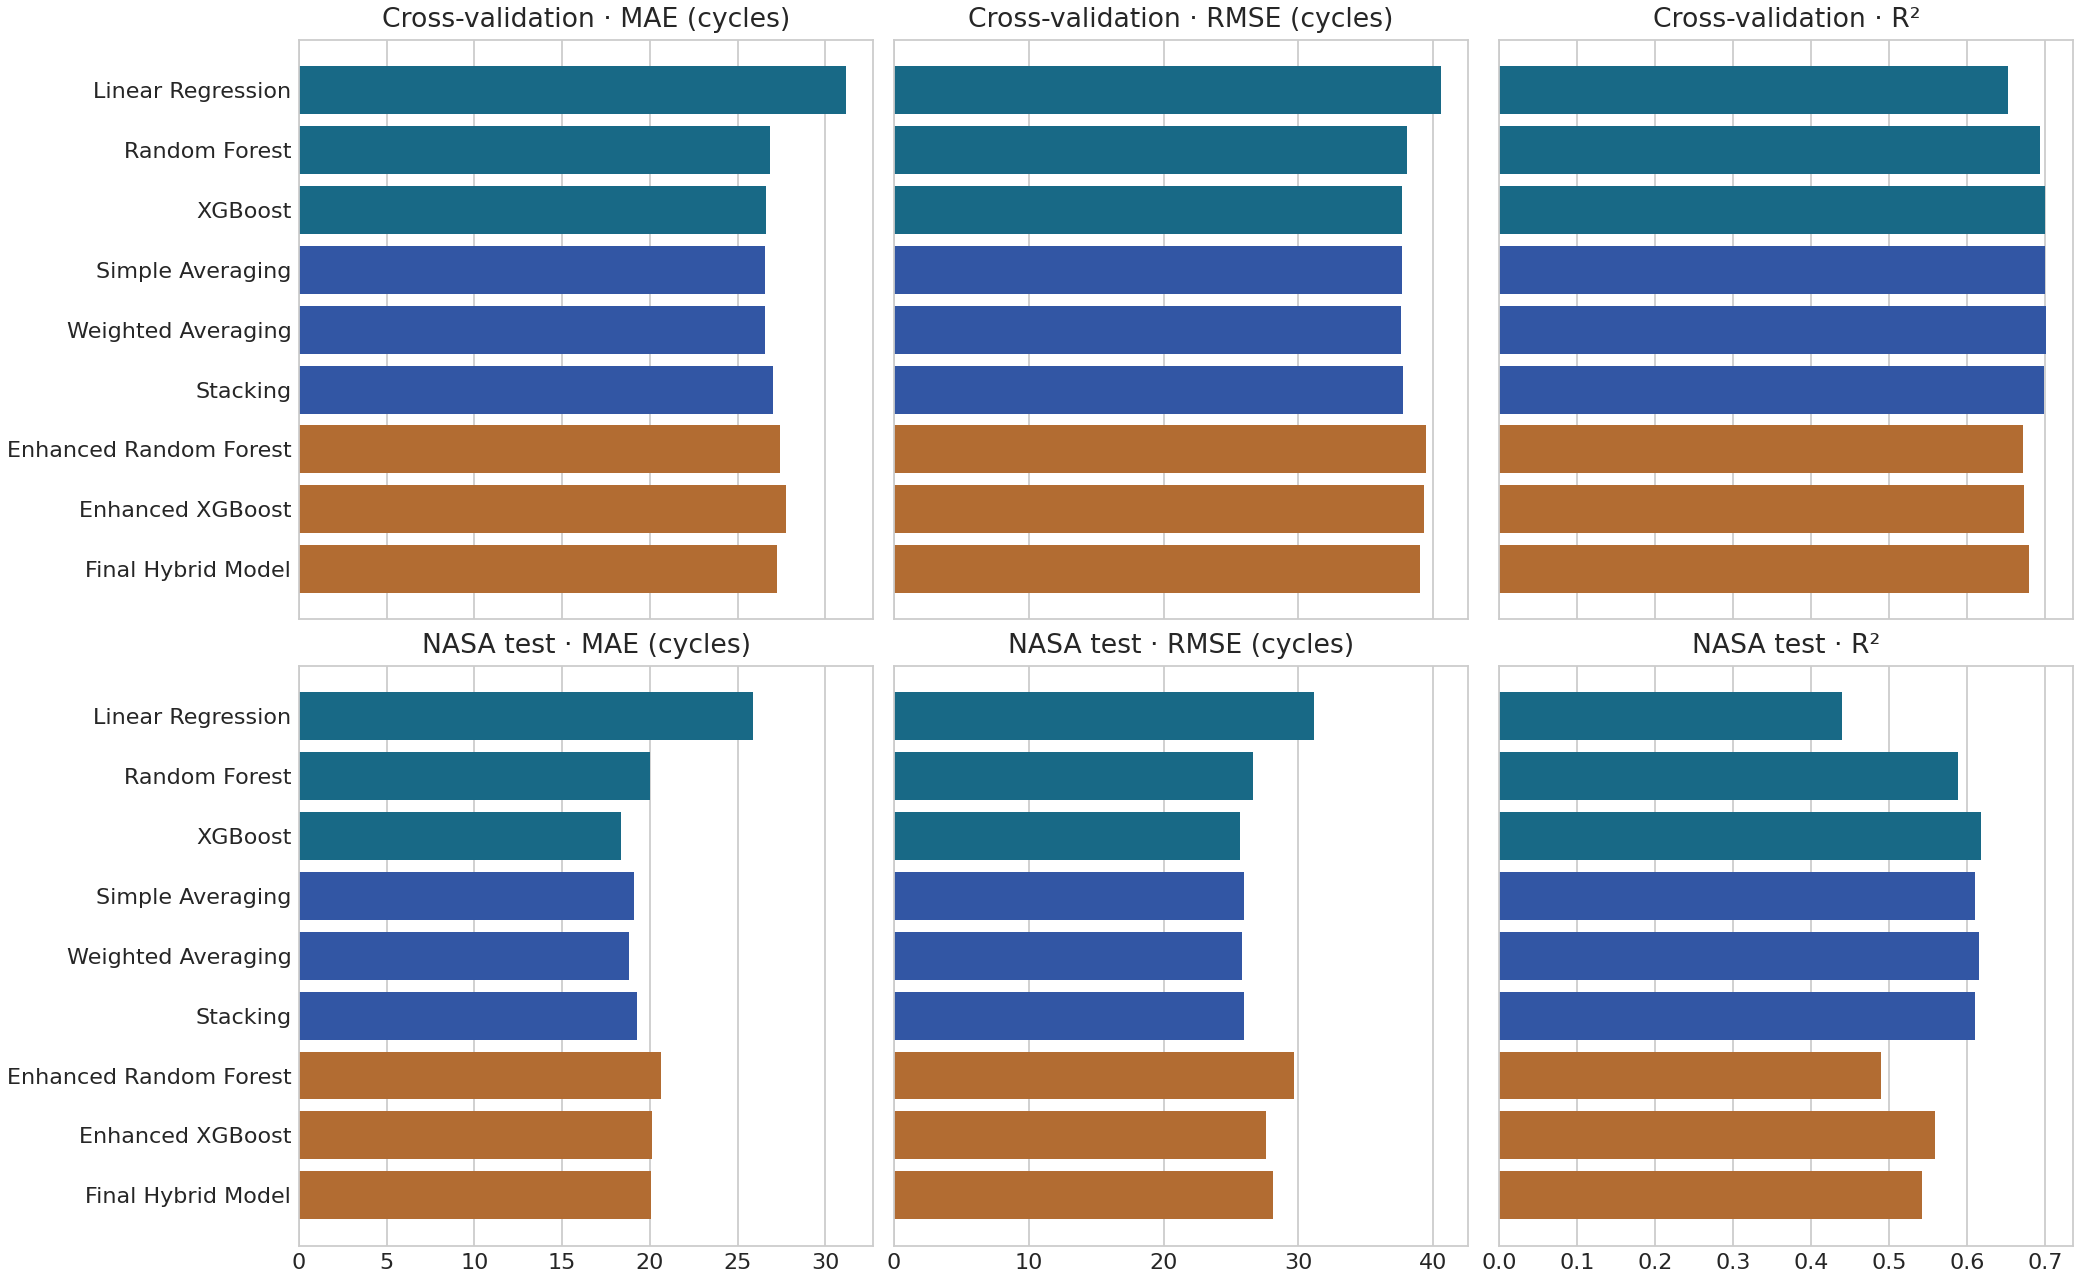

In [6]:
display(master[["Group", *metrics, "NASA Score"]].rename(columns=labels).round(4))
display(pd.read_csv(insights_dir / "lowest_mae_by_group.csv").rename(columns={"R2": "R²"}).round(4))
display(Image(filename=str(insights_dir / "cv_and_nasa_test_comparison.png")))

## Error by actual RUL

Positive signed error represents RUL overestimation. The absolute-error panel shows average magnitude by actual-RUL range.

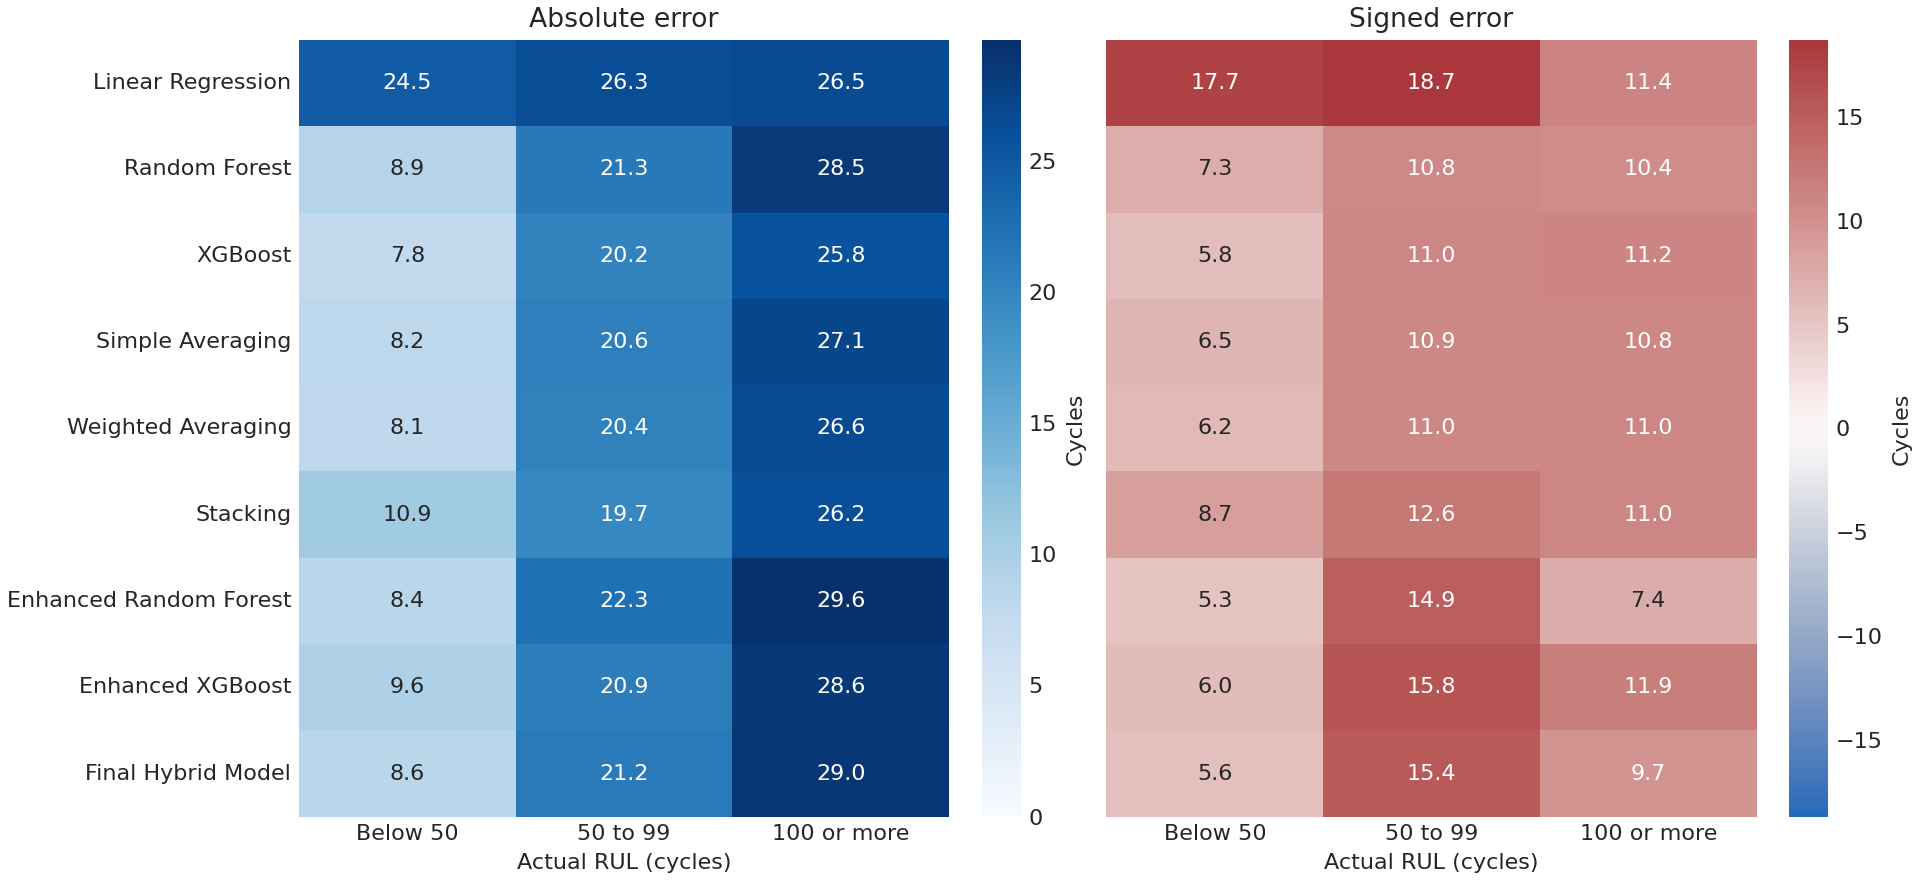

In [7]:
display(Image(filename=str(insights_dir / "errors_by_actual_rul.png")))

In [8]:
report = (insights_dir / "README.md").read_text(encoding="utf-8")
display(Markdown(report[report.index("## Strongest results"):]))

## Strongest results

The lowest reported CV MAE was **Weighted Averaging** at **26.54 cycles**. The lowest NASA test MAE was **XGBoost** at **18.36 cycles**.

- Lowest test RMSE was XGBoost at 25.69 cycles.
- Highest test R² was XGBoost at 0.6179.
- Lowest NASA PHM score was Stacking at 6096.54. The score penalizes RUL overestimates more heavily. [PHM 2008 scoring reference](https://ntrs.nasa.gov/api/citations/20205001125/downloads/Run_to_Failure_Simulation_Under_Real_Flight_Conditions_Dataset.pdf)

See the lowest-MAE table for the individual, ensemble, and hybrid leaders in each evaluation.

## Averaging and stacking

- Simple Averaging had 0.06 cycles lower MAE in CV and 0.74 cycles higher MAE on the NASA test set compared with XGBoost.
- Weighted Averaging had 0.08 cycles lower MAE in CV and 0.43 cycles higher MAE on the NASA test set compared with XGBoost.
- Stacking had 0.47 cycles higher MAE in CV and 0.18 cycles higher MAE on the NASA test set compared with Simple Averaging.
- Stacking had 0.49 cycles higher MAE in CV and 0.49 cycles higher MAE on the NASA test set compared with Weighted Averaging.

The historical weighted CV score was reported on the folds used to choose its weights. The historical stacking CV used global out-of-fold base predictions, so some meta-training inputs depended on outer validation engines. The final stack learned its meta-model only from training-side, engine-held-out predictions and scored the separate NASA test engines once.

## Engineered features

- Enhanced Random Forest had 0.55 cycles higher MAE in CV and 0.60 cycles higher MAE on the NASA test set compared with Random Forest.
- Enhanced XGBoost had 1.15 cycles higher MAE in CV and 1.76 cycles higher MAE on the NASA test set compared with XGBoost.
- Final Hybrid Model had 0.69 cycles higher MAE in CV and 0.97 cycles higher MAE on the NASA test set compared with Simple Averaging.

The rolling summaries may smooth useful short-lived changes or add correlated inputs alongside the raw readings. These comparisons measure the combined feature set at the existing model settings.

## Error patterns and limitations

For XGBoost, the highest endpoint MAE occurred in the **100 or more cycles** actual-RUL range. Its MAE was **25.76** over **34 engines**, with a mean signed error of **+11.20 cycles**. Signed error is predicted minus actual RUL. A positive value means the model predicted too much remaining life.

Engine 15 accounted for **49.4%** of the Enhanced Random Forest PHM score. Its actual RUL was 83 cycles and the model predicted 195.7. Large endpoint errors can dominate the aggregate PHM score.

FD001 is a simulated benchmark and the test set contains a single censored endpoint per engine. Endpoint accuracy does not measure the consistency of predictions earlier in an engine's life. Similar readings at different latent degradation states and differences in engine life can make RUL difficult to distinguish. These are possible explanations rather than causal findings from the error tables. The reported rankings have sampling uncertainty, particularly when MAE differences are small.

## Technical conclusion

The strongest observed FD001 generalization by MAE came from **XGBoost**. Cross-validation and held-out performance are presented separately. The paired comparisons show where the ensemble or feature changes helped at the frozen settings, and the signed-error results show where maintenance timing would be most affected by overestimation.
